# 03 · H3: Did tariffed sectors redirect their exports to other markets?

**Hypothesis H3.** Tariffed sectors sold less to the US but did not redirect to other markets.

**Frozen rule.** Offset ratio = change in exports to other countries ÷ |change in exports to the US|, computed only when exports to the US fell. Confirmed if the ratio is below 0.25, rejected if above 0.75, partial in between.

**Method in plain words.** For each sector (steel, aluminum, copper, autos and parts, softwood lumber) the ratio asks: for every dollar lost in the US, how many cents were gained elsewhere? Each sector's window starts in the first full month after its own first US tariff and covers the latest 12 months (softwood lumber has fewer months, because its tariff started in October 2025). The baseline uses the same calendar months, so seasons match.

**Comparison group.** Products outside the five sectors with no sector-specific US tariff in that month ("no sector-specific tariff"). Their exports to the US did not fall, so the ratio is not defined for them; the % changes to the US and to other countries are shown instead.

All numbers come from `mart_redirection` and `mart_redirection_no_sector_tariff`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display

from src import analysis
from src.common import load_settings

pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.max_colwidth", 60)
con = analysis.connect()
start, end = analysis.tariff_window(con)
print(f"Tariff period (latest 12 months): {start} to {end}")

Tariff period (latest 12 months): Oct 2025 to Sep 2026


## Offset ratio and verdict by sector, both baselines

Values in CAD billions for the window (annual equivalent for 12-month windows).

In [2]:
rows = []
for baseline, label in analysis.BASELINES.items():
    for r in analysis.h3(con, baseline):
        rows.append({
            "baseline": label, "sector": r["label"],
            "window": f"{r['window_start']:%b %Y}–{r['window_end']:%b %Y} ({r['n_months']} months)",
            "US, baseline": r["x_us_base"] / 1e9, "US, latest": r["x_us_tariff"] / 1e9,
            "other, baseline": r["x_nonus_base"] / 1e9, "other, latest": r["x_nonus_tariff"] / 1e9,
            "US change (%)": 100 * r["d_us_pct"], "other change (%)": 100 * r["d_nonus_pct"],
            "offset ratio": r["offset_ratio"], "H3 verdict": r["verdict"],
        })
h3_table = pd.DataFrame(rows)
h3_table

,baseline,sector,window,"US, baseline","US, latest","other, baseline","other, latest",US change (%),other change (%),offset ratio,H3 verdict
0,2022–2024,Steel,Oct 2025–Sep 2026 (12 months),16.532,7.572,1.027,0.896,-54.199,-12.768,-0.015,confirmed
1,2022–2024,Aluminum,Oct 2025–Sep 2026 (12 months),14.610,11.712,0.849,3.292,-19.836,287.527,0.843,rejected
2,2022–2024,Copper,Oct 2025–Sep 2026 (12 months),2.732,0.543,0.083,0.826,-80.126,897.237,0.339,partial
3,2022–2024,Autos and parts,Oct 2025–Sep 2026 (12 months),64.948,56.879,4.029,5.000,-12.423,24.103,0.120,confirmed
4,2022–2024,Softwood lumber,Nov 2025–Sep 2026 (11 months),13.627,9.100,2.573,2.436,-33.222,-5.317,-0.030,confirmed
5,2023–2024,Steel,Oct 2025–Sep 2026 (12 months),16.115,7.572,1.011,0.896,-53.013,-11.389,-0.013,confirmed
6,2023–2024,Aluminum,Oct 2025–Sep 2026 (12 months),14.153,11.712,0.922,3.292,-17.249,257.161,0.971,rejected
7,2023–2024,Copper,Oct 2025–Sep 2026 (12 months),2.817,0.543,0.090,0.826,-80.722,813.894,0.323,partial
8,2023–2024,Autos and parts,Oct 2025–Sep 2026 (12 months),70.811,56.879,4.103,5.000,-19.674,21.861,0.064,confirmed
9,2023–2024,Softwood lumber,Nov 2025–Sep 2026 (11 months),11.642,9.100,2.307,2.436,-21.834,5.602,0.051,confirmed


In [3]:
t = load_settings()["thresholds"]
for sector in h3_table["sector"].unique():
    sub = h3_table[h3_table["sector"] == sector]
    p, s = sub.iloc[0], sub.iloc[1]
    same = "same verdict" if p["H3 verdict"] == s["H3 verdict"] else "VERDICT CHANGES"
    print(f"{sector}: offset ratio {p['offset ratio']:+.3f} (2022–2024, {p['H3 verdict']}) and "
          f"{s['offset ratio']:+.3f} (2023–2024, {s['H3 verdict']}); {same}.")
print(f"Thresholds: confirmed below {t['h3_offset_ratio_confirm_below']}, rejected above "
      f"{t['h3_offset_ratio_reject_above']}.")

Steel: offset ratio -0.015 (2022–2024, confirmed) and -0.013 (2023–2024, confirmed); same verdict.
Aluminum: offset ratio +0.843 (2022–2024, rejected) and +0.971 (2023–2024, rejected); same verdict.
Copper: offset ratio +0.339 (2022–2024, partial) and +0.323 (2023–2024, partial); same verdict.
Autos and parts: offset ratio +0.120 (2022–2024, confirmed) and +0.064 (2023–2024, confirmed); same verdict.
Softwood lumber: offset ratio -0.030 (2022–2024, confirmed) and +0.051 (2023–2024, confirmed); same verdict.
Thresholds: confirmed below 0.25, rejected above 0.75.


## Comparison group: no sector-specific tariff

The group is built month by month from the tariff scope table. It is shown with all goods and without gold and energy, because gold dominates the growth to other countries.

In [4]:
rows = []
for baseline, label in analysis.BASELINES.items():
    for window in ["steel", "lumber"]:
        for variant in ["all", "ex_gold_ex_energy"]:
            g = analysis.no_sector_tariff(con, baseline, window, variant)
            rows.append({
                "baseline": label,
                "window": f"{g['window_start']:%b %Y}–{g['window_end']:%b %Y}",
                "variant": variant,
                "US change (%)": 100 * g["d_us_pct"], "other change (%)": 100 * g["d_nonus_pct"],
                "US change (CAD bn)": g["d_us"] / 1e9, "other change (CAD bn)": g["d_nonus"] / 1e9,
            })
pd.DataFrame(rows)

,baseline,window,variant,US change (%),other change (%),US change (CAD bn),other change (CAD bn)
0,2022–2024,Oct 2025–Sep 2026,all,1.083,49.465,3.915,71.024
1,2022–2024,Oct 2025–Sep 2026,ex_gold_ex_energy,8.493,13.059,15.339,13.677
2,2022–2024,Nov 2025–Sep 2026,all,1.931,50.989,6.375,66.295
3,2022–2024,Nov 2025–Sep 2026,ex_gold_ex_energy,9.545,14.741,15.666,13.928
4,2023–2024,Oct 2025–Sep 2026,all,3.226,52.322,11.420,73.717
5,2023–2024,Oct 2025–Sep 2026,ex_gold_ex_energy,6.945,15.990,12.724,16.323
6,2023–2024,Nov 2025–Sep 2026,all,4.193,54.290,13.548,69.077
7,2023–2024,Nov 2025–Sep 2026,ex_gold_ex_energy,7.827,17.422,13.051,16.085


The 12-month window (Oct 2025–Sep 2026) is the same for steel, aluminum, copper and autos; softwood lumber has its own 11-month window.

## HS4 detail inside each sector

Largest HS4 headings by baseline exports to the US, 2022–2024 baseline. The ratio is shown only where exports to the US fell.

In [5]:
for key, label in analysis.SECTORS.items():
    detail = pd.DataFrame(analysis.h3_hs4(con, "primary", key))[
        ["code", "x_us_base", "x_us_tariff", "x_nonus_base", "x_nonus_tariff", "d_us_pct", "d_nonus_pct", "offset_ratio"]
    ].head(6)
    for col in ["x_us_base", "x_us_tariff", "x_nonus_base", "x_nonus_tariff"]:
        detail[col] = detail[col] / 1e9
    print(f"\n{label} (CAD billions)")
    display(detail.rename(columns={"code": "HS4"}))


Steel (CAD billions)


,HS4,x_us_base,x_us_tariff,x_nonus_base,x_nonus_tariff,d_us_pct,d_nonus_pct,offset_ratio
0,7308,2.102,1.153,0.046,0.102,-0.452,1.229,0.059
1,7208,2.012,0.280,0.051,0.029,-0.861,-0.429,-0.013
2,7210,1.782,0.849,0.083,0.077,-0.524,-0.074,-0.007
3,7306,1.781,0.943,0.049,0.078,-0.471,0.615,0.036
4,7326,1.391,0.628,0.099,0.078,-0.549,-0.208,-0.027
5,7225,1.099,0.363,0.076,0.124,-0.670,0.636,0.065



Aluminum (CAD billions)


,HS4,x_us_base,x_us_tariff,x_nonus_base,x_nonus_tariff,d_us_pct,d_nonus_pct,offset_ratio
0,7601,10.742,8.616,0.659,3.010,-0.198,3.570,1.106
1,7610,0.970,0.545,0.028,0.042,-0.439,0.535,0.035
2,7605,0.862,0.996,0.015,0.026,0.156,0.746,NaN
3,7606,0.787,0.642,0.018,0.036,-0.184,1.056,0.129
4,7604,0.721,0.514,0.005,0.006,-0.287,0.203,0.005
5,7616,0.392,0.230,0.110,0.147,-0.412,0.333,0.227



Copper (CAD billions)


,HS4,x_us_base,x_us_tariff,x_nonus_base,x_nonus_tariff,d_us_pct,d_nonus_pct,offset_ratio
0,7408,2.419,0.244,0.010,0.779,-0.899,74.763,0.354
1,7411,0.237,0.232,0.021,0.040,-0.018,0.902,4.364
2,7412,0.024,0.023,0.002,0.002,-0.012,0.040,0.240
3,7409,0.017,0.009,0.001,0.001,-0.480,0.337,0.035
4,7419,0.015,0.010,0.002,0.002,-0.345,-0.115,-0.039
5,7415,0.008,0.005,0.001,0.001,-0.399,0.163,0.060



Autos and parts (CAD billions)


,HS4,x_us_base,x_us_tariff,x_nonus_base,x_nonus_tariff,d_us_pct,d_nonus_pct,offset_ratio
0,8703,39.840,32.353,2.281,3.274,-0.188,0.435,0.133
1,8708,14.943,15.466,1.605,1.525,0.035,-0.050,NaN
2,8704,7.781,6.031,0.067,0.103,-0.225,0.530,0.020
3,8702,0.988,1.585,0.003,0.005,0.605,0.495,NaN
4,8705,0.668,0.676,0.021,0.006,0.012,-0.701,NaN
5,8707,0.261,0.401,0.017,0.006,0.535,-0.629,NaN



Softwood lumber (CAD billions)


,HS4,x_us_base,x_us_tariff,x_nonus_base,x_nonus_tariff,d_us_pct,d_nonus_pct,offset_ratio
0,4407,8.307,5.180,1.481,1.322,-0.376,-0.107,-0.051
1,4410,3.162,1.941,0.075,0.046,-0.386,-0.386,-0.024
2,4412,0.584,0.520,0.017,0.015,-0.109,-0.133,-0.035
3,4411,0.567,0.449,0.014,0.011,-0.208,-0.209,-0.024
4,4408,0.428,0.391,0.009,0.006,-0.088,-0.277,-0.063
5,4409,0.196,0.249,0.018,0.015,0.267,-0.146,NaN


## Chart

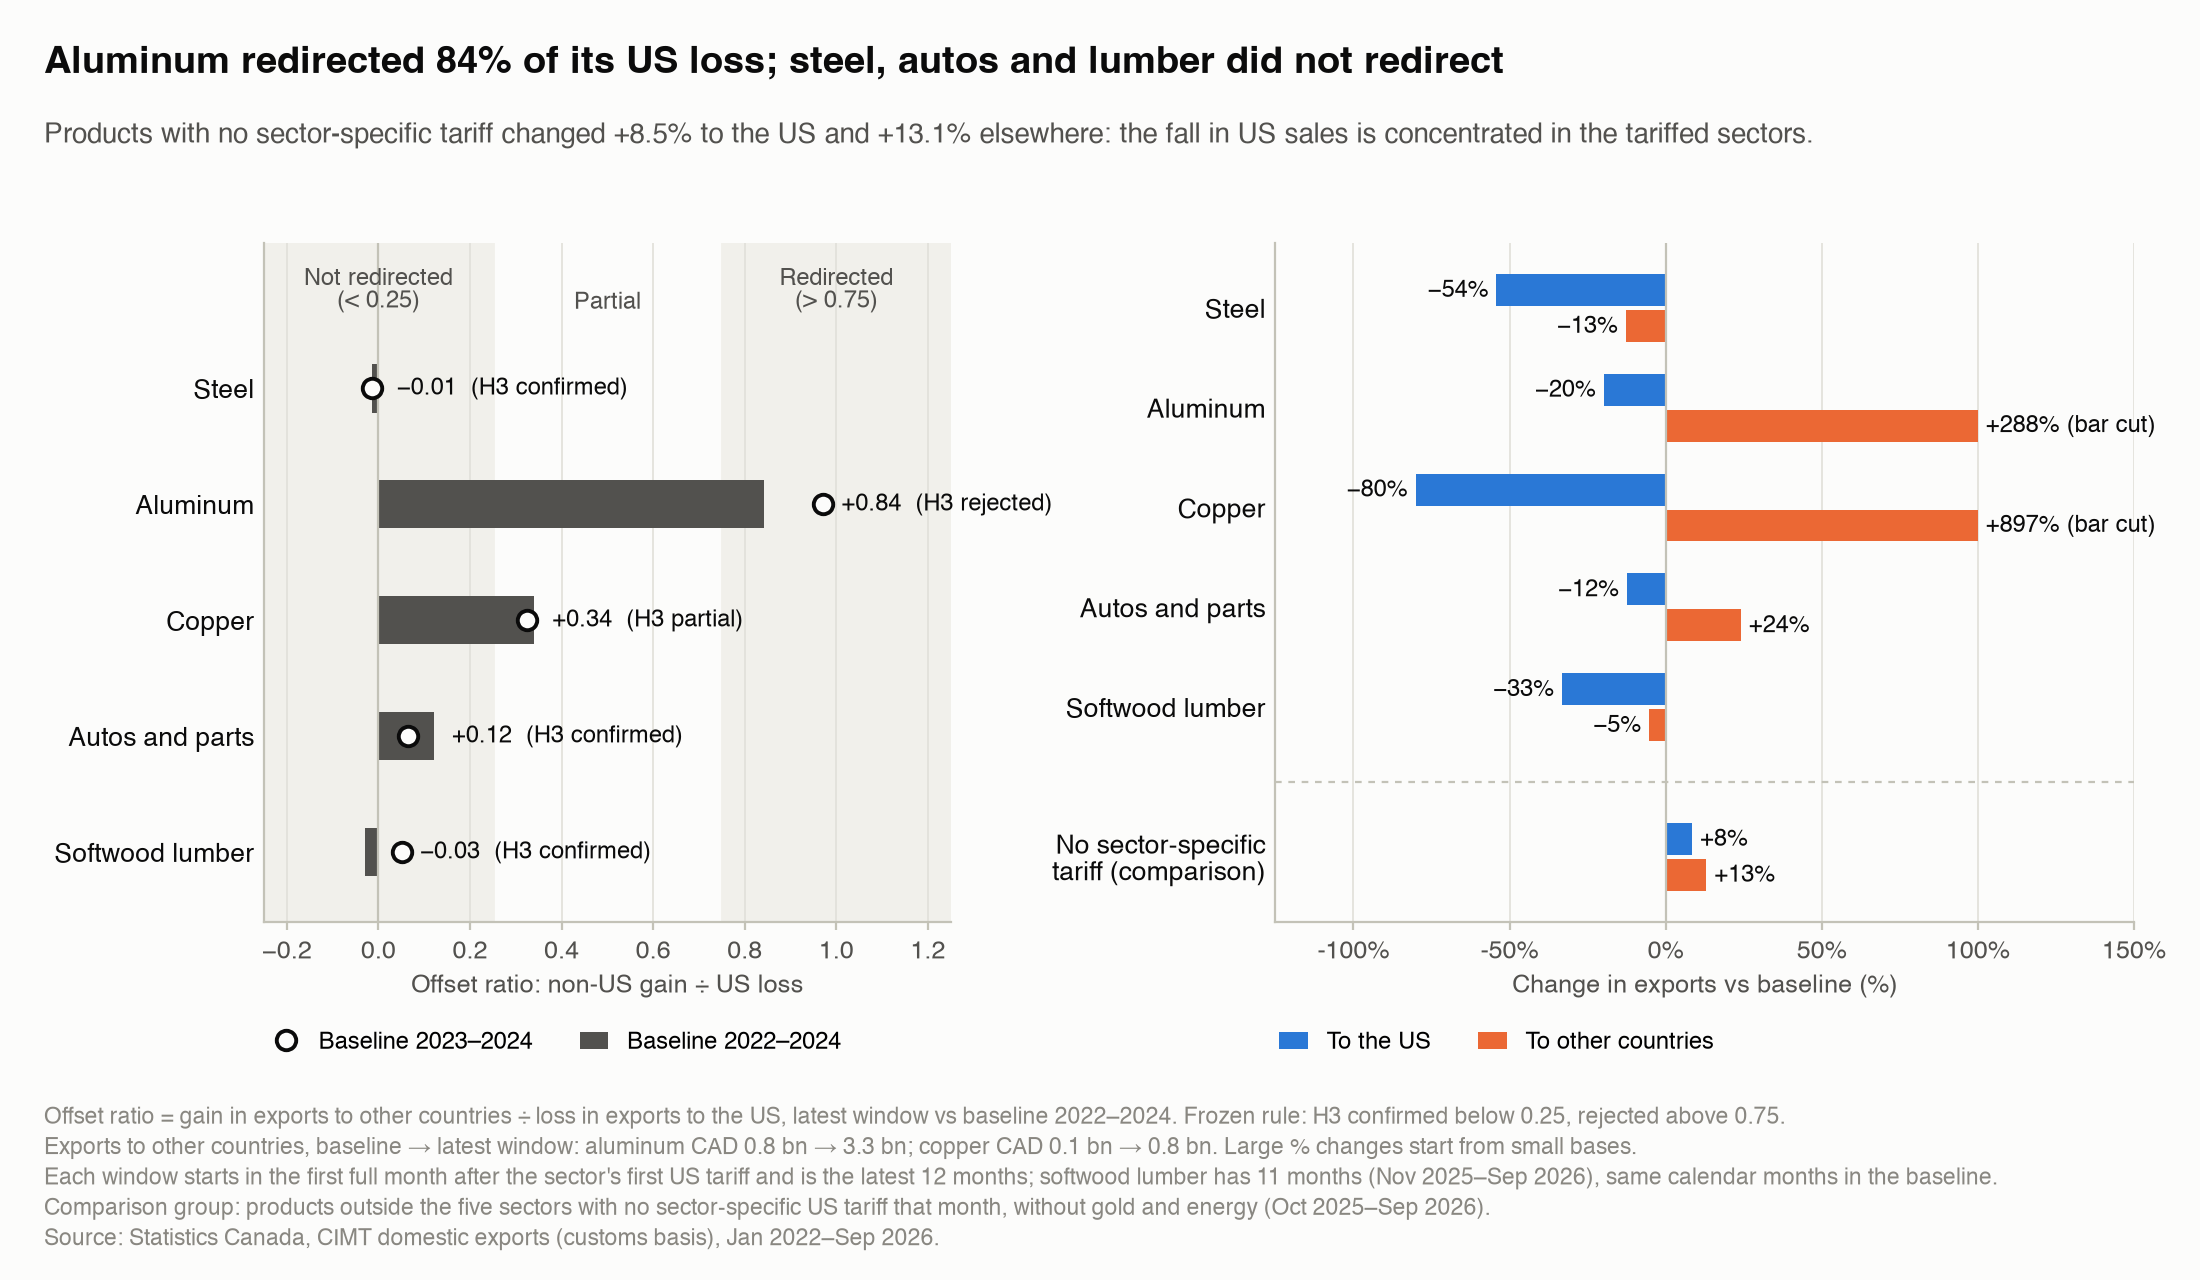

In [6]:
display(Image(filename=str(ROOT / "figures" / "h3_redirection.png"), width=1000))

## Notes

- Products in the comparison group that did not qualify for USMCA still paid across-the-board US duties (IEEPA, March 2025 to February 2026, then Section 122 and Section 301). The tariff scope table tracks only sector-specific measures.
- Softwood lumber already paid US anti-dumping and countervailing duties before 2025.
- This is a description of the data. It does not show that tariffs caused the changes.